# DUPIN-Mini: Small-Scale Reproduction of DUPIN's Core Claim (DARPA TC E3-CADETS)

**Paper:** Bae et al., *"DUPIN: Attack Learning Is Still Needed! Demonstrating
Few-Shot after Unsupervised Pretraining Is A Nimble Forensics Learner"*, USENIX
Security 2026.

**Goal of this notebook:** reproduce, at small scale, the paper's central claim:

> Unsupervised pretraining on benign provenance graphs + few-shot fine-tuning
> on a handful of labeled attack samples outperforms (a) training the same
> model from scratch, and (b) one-class / outlier-detection baselines that
> never see attack data.

This is **not** a full-scale replication (the paper uses up to 7.3 TB of logs
and 25 APT campaigns). It uses one real DARPA Transparent Computing
**Engagement 3, CADETS** provenance graph -- the same tracepoint and attack
family (Backdoor Nginx) as Attack ID 1 in DUPIN's Table 2.

**Shortcut used here:** downloading and parsing the raw DARPA CDM logs
requires a multi-GB Google Drive dump with no dates in the filenames, a Java
toolchain, and manual ground-truth matching against a long PDF report. We
avoid all of that by reusing the **pre-processed graph files that the MAGIC
paper (Jia et al., USENIX Security 2024 -- one of DUPIN's own baselines)
ships directly in its GitHub repository** (`FDUDSDE/MAGIC`). These are
already-parsed DGL graphs with node-level ground truth (malicious node IDs)
included -- no PDF reading or keyword matching required.

**What this buys us, structurally:**
- Real DARPA CADETS E3 data (not a synthetic stand-in like StreamSpot)
- Semantically meaningful node types (process / file / socket / ...) and
  edge types (read / write / execute / connect / ... -- matching DUPIN's
  Table 1), instead of StreamSpot's opaque single-character types
- Ground truth already provided at the **node** level via `metadata.json`'s
  `malicious` list -- no ambiguity

## 0. Setup

Run this on Kaggle with a GPU accelerator enabled (Settings -> Accelerator ->
GPU P100 or T4), and **internet access enabled** (Settings -> Internet -> On)
so the notebook can `git clone` MAGIC's repo directly.

This notebook needs `dgl` in addition to the usual PyTorch/scikit-learn
stack, since MAGIC's pre-processed files are serialized `DGLGraph` objects.

**Known dgl issues on Kaggle, both worked around below:**
1. `pip install dgl` pulls a version whose `graphbolt` submodule (a
   large-scale sampling feature we never use here) ships a compiled `.so`
   that often doesn't match Kaggle's exact torch/CUDA build, causing
   `FileNotFoundError: Cannot find DGL C++ graphbolt library ...` on
   `import dgl`. We work around this by stubbing out `dgl.graphbolt` with
   an empty module *before* importing `dgl`, so it's never actually loaded.
2. Older `dgl` releases (pre-2.x, which predate the `graphbolt` feature
   entirely) generally aren't published as wheels for newer Python
   versions, so downgrading isn't a reliable fix -- the stub approach below
   is more robust than pinning an old version.

In [1]:
import subprocess, sys
subprocess.run([sys.executable, "-m", "pip", "install", "-q", "dgl"], check=True)

import types
sys.modules["dgl.graphbolt"] = types.ModuleType("dgl.graphbolt")  # see note above

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 8.6/8.6 MB 12.8 MB/s eta 0:00:00


In [2]:
import os, random, math, zipfile
from collections import defaultdict

import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from sklearn.ensemble import IsolationForest
from sklearn.metrics import roc_auc_score, confusion_matrix
import pandas as pd
import dgl
import pickle as pkl
import json as jsonlib

SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)

DGL backend not selected or invalid.  Assuming PyTorch for now.


Setting the default backend to "pytorch". You can change it in the ~/.dgl/config.json file or export the DGLBACKEND environment variable.  Valid options are: pytorch, mxnet, tensorflow (all lowercase)
Using device: cuda


## 1. Download the pre-processed CADETS E3 graphs (via MAGIC's repo)

Only the `data/cadets/graphs.zip` file is needed (~8 MB compressed, ~490 MB
uncompressed) -- we don't need the rest of the MAGIC repository (its model
code, checkpoints for other datasets, etc.), but cloning the whole repo is
simplest since GitHub doesn't let us fetch a single subfolder without extra
tooling.

If Kaggle's internet access is disabled for your notebook, clone
`FDUDSDE/MAGIC` locally, upload the extracted `data/cadets/` folder as a
Kaggle Dataset, and point `CADETS_DIR` at it instead.

In [3]:
REPO_DIR = "/kaggle/working/MAGIC"
CADETS_DIR = os.path.join(REPO_DIR, "data", "cadets")

if not os.path.isfile(os.path.join(CADETS_DIR, "metadata.json")):
    if not os.path.isdir(REPO_DIR):
        subprocess.run(
            ["git", "clone", "--depth", "1", "https://github.com/FDUDSDE/MAGIC.git", REPO_DIR],
            check=True,
        )
    with zipfile.ZipFile(os.path.join(CADETS_DIR, "graphs.zip")) as zf:
        zf.extractall(CADETS_DIR)

assert os.path.isfile(os.path.join(CADETS_DIR, "metadata.json")), "Extraction failed -- check CADETS_DIR"
print("CADETS E3 data ready at", CADETS_DIR)

Cloning into '/kaggle/working/MAGIC'...


CADETS E3 data ready at /kaggle/working/MAGIC/data/cadets


## 2. Load metadata and graphs

- `train0.pkl` .. `train3.pkl`: four **benign-only** provenance graphs
  (different days/segments of the CADETS E3 capture) -- our pretraining
  corpus.
- `test0.pkl`: one graph containing **both** benign activity and the
  Backdoor-Nginx attack -- our source for few-shot fine-tuning and
  evaluation.
- `metadata.json`'s `malicious` field: a list of malicious node IDs for each
  test graph (here just one list, since there's one test graph).

In [4]:
with open(os.path.join(CADETS_DIR, "metadata.json")) as f:
    metadata = jsonlib.load(f)

NODE_FEATURE_DIM = metadata["node_feature_dim"]   # distinct node "type" classes
EDGE_FEATURE_DIM = metadata["edge_feature_dim"]   # distinct edge "type" classes
MALICIOUS_NODE_IDS = set(metadata["malicious"][0])

print(f"node_feature_dim={NODE_FEATURE_DIM}, edge_feature_dim={EDGE_FEATURE_DIM}")
print(f"n_train_graphs={metadata['n_train']}, n_test_graphs={metadata['n_test']}")
print(f"malicious nodes in test graph: {len(MALICIOUS_NODE_IDS)}")

train_graphs = [pkl.load(open(os.path.join(CADETS_DIR, f"train{i}.pkl"), "rb"))
                for i in range(metadata["n_train"])]
test_graph = pkl.load(open(os.path.join(CADETS_DIR, "test0.pkl"), "rb"))

print("Train graph sizes (nodes, edges):",
      [(g.num_nodes(), g.num_edges()) for g in train_graphs])
print("Test graph size (nodes, edges):", (test_graph.num_nodes(), test_graph.num_edges()))

node_feature_dim=6, edge_feature_dim=27
n_train_graphs=4, n_test_graphs=1
malicious nodes in test graph: 12846
Train graph sizes (nodes, edges): [(386403, 738142), (362637, 714073), (275269, 563229), (245553, 447521)]
Test graph size (nodes, edges): (357173, 840299)


## 3. Convert DGL graphs to plain adjacency lists

We only need `dgl` for this one-time load. Everything downstream operates on
plain Python/NumPy structures, which keeps the rest of the notebook simple
and dependency-light.

In [5]:
def dgl_to_adjacency(g):
    '''Build a directed adjacency map: node -> list of (neighbor, edge_type, direction).
    'direction'=='out' means the true edge is (node -> neighbor);
    'direction'=='in'  means the true edge is (neighbor -> node).
    Both directions are stored on both endpoints so random-walk exploration
    (Section 3.2 / Appendix E of DUPIN) can traverse edges either way while
    the TRUE direction is preserved for the edge tensor fed to the model.
    '''
    src, dst = g.edges()
    src = src.numpy(); dst = dst.numpy()
    edge_type = g.edata["type"].numpy().reshape(-1)
    node_type = g.ndata["type"].numpy().reshape(-1)

    adj = defaultdict(list)
    for s, d, et in zip(src, dst, edge_type):
        adj[int(s)].append((int(d), int(et), "out"))
        adj[int(d)].append((int(s), int(et), "in"))
    return adj, node_type

train_adjs_types = [dgl_to_adjacency(g) for g in train_graphs]
test_adj, test_node_type = dgl_to_adjacency(test_graph)
print("Adjacency maps built.")

Adjacency maps built.


## 4. Random-walk subgraph extraction (DUPIN Appendix E, Algorithm 1)

Following the paper directly this time: starting from a center node, repeatedly
hop to a random neighbor of a node already in the frontier, growing the
subgraph until it reaches size **gamma=40** or the walk fails to find a new
neighbor **delta=100** times in a row -- exactly DUPIN's own parameters
(Section 3.2: "We set gamma=40, delta=100 for this paper").

In [6]:
GAMMA = 40   # target subgraph size, per DUPIN Section 3.2
DELTA = 100  # max stalled iterations before giving up, per DUPIN Section 3.2

def extract_ego_subgraph(adj, center, gamma=GAMMA, delta=DELTA):
    visited = [center]
    visited_idx = {center: 0}
    frontier = [center]
    edges = []  # (local_src, local_dst, edge_type)
    n_iters = 0
    while len(visited) < gamma and n_iters < delta and frontier:
        n_iters += 1
        cur = random.choice(frontier)
        neighbors = adj.get(cur, [])
        if not neighbors:
            frontier.remove(cur)
            continue
        nbr, etype, direction = random.choice(neighbors)
        if nbr not in visited_idx:
            visited_idx[nbr] = len(visited)
            visited.append(nbr)
            frontier.append(nbr)
        if direction == "out":
            edges.append((visited_idx[cur], visited_idx[nbr], etype))
        else:
            edges.append((visited_idx[nbr], visited_idx[cur], etype))
    return visited, edges

class GraphSample:
    __slots__ = ["label", "node_tokens", "edge_index", "edge_types"]
    def __init__(self, label, node_tokens, edge_index, edge_types):
        self.label = label
        self.node_tokens = node_tokens
        self.edge_index = edge_index
        self.edge_types = edge_types

def build_sample(adj, node_type_arr, center, malicious_set=frozenset()):
    '''Extract a subgraph starting from `center` and label it AFTER the
    fact: attack (1) if ANY node the walk happens to visit is a known
    malicious entity, benign (0) otherwise. Crucially, `center` itself is
    chosen without looking at ground truth (see the sampling loop below) --
    only the resulting subgraph's *contents* are checked against
    `malicious_set`. This follows DUPIN's own evaluation principle
    (Section 4, principle 2): 'the attack ground truth must not be
    utilized in any form' during subgraph collection, only afterward for
    labeling.
    '''
    visited, edges = extract_ego_subgraph(adj, center)
    if len(edges) < 1:
        return None
    label = 1 if any(v in malicious_set for v in visited) else 0
    node_tokens = [int(node_type_arr[n]) + 1 for n in visited]  # +1 reserves id 0 for [MASK]
    src = [e[0] for e in edges]; dst = [e[1] for e in edges]; et = [e[2] for e in edges]
    return GraphSample(
        label,
        torch.tensor(node_tokens, dtype=torch.long),
        torch.tensor([src, dst], dtype=torch.long),
        torch.tensor(et, dtype=torch.long),
    )

## 5. Build pretraining / few-shot / test sets

**Important methodological note:** an earlier version of this notebook
picked known-malicious node IDs as the random-walk *starting point* for
attack-labeled samples. That leaks the label into the input: the center
node's own type ends up dominating the graph representation (mean-pooled
over all visited nodes), so *any* classifier -- even a one-class detector
that never sees labels -- can "cheat" by reading the center node's type
back out, without learning anything about actual attack *context*. This
mirrors exactly the pitfall DUPIN's own Section 4 (evaluation principle 2)
warns about: *"one may mistakenly allow [the] search algorithm to start
from an attack entity ... the attack ground truth must not be utilized in
any form"* during subgraph collection.

The fix: pick the random-walk starting node **uniformly at random from the
entire graph**, exactly as we already do for pretraining, with no
knowledge of ground truth. Only *after* a subgraph has been collected do we
check whether it happens to contain a malicious node anywhere in it, and
label it accordingly. We keep sampling until we've collected enough
attack-labeled and benign-labeled subgraphs this way.

- **Pretraining**: random center nodes across the 4 benign training graphs
  -- no attack data involved at all (unchanged).
- **Few-shot fine-tuning + held-out test**: random center nodes from the
  test graph, labeled after the fact by whether the resulting subgraph
  touches a known-malicious node.

In [7]:
N_PRETRAIN_SAMPLES = 400
N_FEWSHOT_ATTACK = 5
N_FEWSHOT_BENIGN = 5
N_TEST_ATTACK = 30
N_TEST_BENIGN = 30
MAX_SAMPLING_ATTEMPTS = 20000

# ---- Pretraining corpus (benign only) ----
pretrain_samples = []
attempts = 0
while len(pretrain_samples) < N_PRETRAIN_SAMPLES and attempts < N_PRETRAIN_SAMPLES * 3:
    attempts += 1
    g_idx = random.randrange(len(train_adjs_types))
    adj, node_type_arr = train_adjs_types[g_idx]
    center = random.choice(list(adj.keys()))
    s = build_sample(adj, node_type_arr, center)   # malicious_set left empty -> always label 0
    if s is not None:
        pretrain_samples.append(s)
print(f"Pretraining samples: {len(pretrain_samples)}")

# ---- Few-shot + test pools: UNBIASED random-start sampling from the test graph ----
all_test_nodes = list(test_adj.keys())
needed_attack = N_FEWSHOT_ATTACK + N_TEST_ATTACK
needed_benign = N_FEWSHOT_BENIGN + N_TEST_BENIGN

attack_pool, benign_pool = [], []
attempts = 0
while (len(attack_pool) < needed_attack or len(benign_pool) < needed_benign) \
        and attempts < MAX_SAMPLING_ATTEMPTS:
    attempts += 1
    center = random.choice(all_test_nodes)   # <-- chosen with NO knowledge of ground truth
    s = build_sample(test_adj, test_node_type, center, malicious_set=MALICIOUS_NODE_IDS)
    if s is None:
        continue
    if s.label == 1 and len(attack_pool) < needed_attack:
        attack_pool.append(s)
    elif s.label == 0 and len(benign_pool) < needed_benign:
        benign_pool.append(s)

print(f"Collected via unbiased sampling ({attempts} attempts): "
      f"{len(attack_pool)} attack-labeled, {len(benign_pool)} benign-labeled subgraphs")
if len(attack_pool) < needed_attack or len(benign_pool) < needed_benign:
    print("  [warning] Ran out of attempts before reaching the target counts -- "
          "either raise MAX_SAMPLING_ATTEMPTS, or reduce the N_* targets above. "
          "This can happen if malicious nodes are rare relative to graph size, "
          "so a random walk of size GAMMA rarely touches one.")

random.shuffle(attack_pool)
random.shuffle(benign_pool)

finetune_samples = attack_pool[:N_FEWSHOT_ATTACK] + benign_pool[:N_FEWSHOT_BENIGN]
test_samples = attack_pool[N_FEWSHOT_ATTACK:N_FEWSHOT_ATTACK + N_TEST_ATTACK] \
             + benign_pool[N_FEWSHOT_BENIGN:N_FEWSHOT_BENIGN + N_TEST_BENIGN]
random.shuffle(finetune_samples)
random.shuffle(test_samples)

print(f"Few-shot fine-tuning samples: {len(finetune_samples)} "
      f"({sum(s.label for s in finetune_samples)} attack)")
print(f"Held-out test samples: {len(test_samples)} "
      f"({sum(s.label for s in test_samples)} attack)")

Pretraining samples: 400
Collected via unbiased sampling (194 attempts): 35 attack-labeled, 35 benign-labeled subgraphs
Few-shot fine-tuning samples: 10 (5 attack)
Held-out test samples: 60 (30 attack)


**A note on scale:** if the sampling loop above reports far fewer
attack-labeled subgraphs than requested (or times out), it means malicious
nodes are sparse relative to the graph and a `GAMMA=40`-sized random walk
rarely happens to touch one. Try raising `GAMMA` (bigger subgraphs cover
more ground per walk), raising `MAX_SAMPLING_ATTEMPTS`, or lowering the
`N_*` targets to whatever the graph can realistically supply -- DUPIN's own
Table 2 shows some CADETS campaigns have as few as 1-9 labeled attack
entities in total, so a handful of confirmed attack-labeled subgraphs is
already a fair "few-shot" regime, not a shortcoming.</br>
</br>
**Class-balance caveat**: because attack-labeled subgraphs are now found by
chance rather than by construction, they may end up systematically larger
or structurally different from benign ones purely because *any* subgraph
touching one of the (comparatively common, per the diagnostic you ran)
type-1 nodes gets swept into the attack pool. If AUROC is still suspiciously
perfect after this fix, that's a sign the type-1-node correlation itself is
strong enough to be a giveaway even without center-node leakage -- worth
reporting as a finding about this dataset/labeling combination, not
necessarily a bug.

## 6. A small Graph Attention Network (GAT)

This mirrors DUPIN's Section 3.3 architecture at a much smaller scale: node
embeddings + edge-type embeddings (Eq. 3-4), single-head attention
aggregation per layer (Eq. 1-2), stacked for 2 layers (the paper uses 7).
Implemented from scratch in plain PyTorch (no `torch_geometric` dependency).

In [8]:
EMBED_DIM = 32   # DUPIN uses 128; shrunk for a fast toy run
VOCAB_SIZE = NODE_FEATURE_DIM + 1   # +1 for [MASK]
N_EDGE_TYPES = EDGE_FEATURE_DIM

class TinyGATLayer(nn.Module):
    def __init__(self, dim):
        super().__init__()
        self.W = nn.Linear(dim, dim, bias=False)
        self.attn = nn.Linear(2 * dim, 1)
        self.edge_proj = nn.Linear(dim, dim)

    def forward(self, h, edge_index, edge_emb):
        src, dst = edge_index
        Wh = self.W(h)
        e = self.attn(torch.cat([Wh[src], Wh[dst]], dim=-1)).squeeze(-1)
        e = F.leaky_relu(e, 0.2)
        e = e - e.max()
        exp_e = torch.exp(e)
        denom = torch.zeros(h.size(0), device=h.device).index_add_(0, dst, exp_e) + 1e-9
        alpha = exp_e / denom[dst]
        msg = alpha.unsqueeze(-1) * (Wh[src] + self.edge_proj(edge_emb))
        out = torch.zeros_like(Wh).index_add_(0, dst, msg)
        return F.elu(out + Wh)

class DupinMiniGAT(nn.Module):
    def __init__(self, vocab_size=VOCAB_SIZE, n_edge_types=N_EDGE_TYPES, dim=EMBED_DIM):
        super().__init__()
        self.node_emb = nn.Embedding(vocab_size, dim)
        self.edge_emb = nn.Embedding(n_edge_types, dim)
        self.layer1 = TinyGATLayer(dim)
        self.layer2 = TinyGATLayer(dim)
        self.node_pred_head = nn.Linear(dim, vocab_size)          # DUPIN Eq. 5
        self.edge_pred_head = nn.Linear(2 * dim, n_edge_types)    # DUPIN Eq. 6
        self.classifier = nn.Linear(dim, 2)                       # DUPIN Section 3.4

    def encode(self, node_tokens, edge_index, edge_types):
        h = self.node_emb(node_tokens)
        e = self.edge_emb(edge_types)
        h = self.layer1(h, edge_index, e)
        h = self.layer2(h, edge_index, e)
        return h

    def forward_classify(self, node_tokens, edge_index, edge_types):
        h = self.encode(node_tokens, edge_index, edge_types)
        graph_repr = h.mean(dim=0, keepdim=True)
        return self.classifier(graph_repr)

## 7. Phase 1 - Unsupervised pretraining (masked prediction)

Following DUPIN Eq. 5-7: randomly mask ~25% of node type tokens and edge
types per subgraph, and train the model to predict them from context --
learning "what normal system structure looks like" *without any attack
labels*.

In [9]:
def to_device(sample):
    return (sample.node_tokens.to(device),
            sample.edge_index.to(device),
            sample.edge_types.to(device))

def pretrain(model, samples, epochs=3, mask_ratio=0.25, lr=1e-3):
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    model.train()
    for epoch in range(epochs):
        random.shuffle(samples)
        total_loss, n_batches = 0.0, 0
        for sample in samples:
            node_tokens, edge_index, edge_types = to_device(sample)
            if edge_index.size(1) < 2:
                continue

            n_mask_nodes = max(1, int(len(node_tokens) * mask_ratio))
            mask_idx = torch.randperm(len(node_tokens), device=device)[:n_mask_nodes]
            gold_tokens = node_tokens[mask_idx].clone()
            masked_input = node_tokens.clone()
            masked_input[mask_idx] = 0

            h = model.encode(masked_input, edge_index, edge_types)
            node_logits = model.node_pred_head(h[mask_idx])
            node_loss = F.cross_entropy(node_logits, gold_tokens)

            n_mask_edges = max(1, int(edge_index.size(1) * mask_ratio))
            e_idx = torch.randperm(edge_index.size(1), device=device)[:n_mask_edges]
            gold_edges = edge_types[e_idx].clone()
            edge_pairs = torch.cat([h[edge_index[0, e_idx]], h[edge_index[1, e_idx]]], dim=-1)
            edge_logits = model.edge_pred_head(edge_pairs)
            edge_loss = F.cross_entropy(edge_logits, gold_edges)

            loss = node_loss + edge_loss
            opt.zero_grad(); loss.backward(); opt.step()
            total_loss += loss.item(); n_batches += 1
        print(f"  [pretrain] epoch {epoch+1}/{epochs}  avg loss = {total_loss/max(n_batches,1):.4f}")
    return model

## 7b. Threshold selection (DUPIN Section 4.2)

DUPIN does **not** use a fixed 0.5 cutoff on the predicted probability.
Instead (Section 4.2, "Threshold"), it scans the ROC curve and picks the
threshold whose point is closest (Euclidean distance) to the ideal corner
`(TPR=1, TNR=1)` -- i.e. it balances catching attacks against not
raising false alarms, rather than assuming 0.5 is meaningful for an
imbalanced detection task. We apply the same rule to all three approaches
below so the comparison is apples-to-apples.

In [10]:
def metrics_at_optimal_threshold(y_true, y_score):
    '''DUPIN Section 4.2: pick the threshold minimizing Euclidean distance
    to the perfect point (TPR=1, TNR=1) on the ROC curve, instead of a
    fixed 0.5 cutoff.'''
    from sklearn.metrics import roc_curve
    y_true = np.asarray(y_true)
    y_score = np.asarray(y_score)

    if len(set(y_true.tolist())) < 2:
        # Degenerate case: only one class present -- ROC/threshold search
        # isn't meaningful, fall back to a fixed 0.5 cutoff.
        y_pred = (y_score > 0.5).astype(int)
    else:
        fpr, tpr, thresholds = roc_curve(y_true, y_score)
        tnr = 1 - fpr
        dist = np.sqrt((1 - tpr) ** 2 + (1 - tnr) ** 2)
        best_idx = np.argmin(dist)
        best_threshold = thresholds[best_idx]
        y_pred = (y_score >= best_threshold).astype(int)

    tn, fp, fn, tp = confusion_matrix(y_true, y_pred, labels=[0, 1]).ravel()
    tpr_final = tp / (tp + fn) if (tp + fn) else 0.0
    tnr_final = tn / (tn + fp) if (tn + fp) else 0.0
    try:
        auroc = roc_auc_score(y_true, y_score)
    except ValueError:
        auroc = float("nan")
    return dict(TPR=tpr_final, TNR=tnr_final, AUROC=auroc, TP=tp, FP=fp, TN=tn, FN=fn)

## 8. Phase 2 - Few-shot fine-tuning on labeled attack samples

Following DUPIN Section 3.4: attach a small classifier on top of the
pretrained representation and fine-tune on a *handful* of labeled examples.

In [11]:
def few_shot_finetune(model, samples, epochs=30, lr=5e-4):
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    model.train()
    for epoch in range(epochs):
        random.shuffle(samples)
        total_loss = 0.0
        for sample in samples:
            node_tokens, edge_index, edge_types = to_device(sample)
            if edge_index.size(1) < 2:
                continue
            logits = model.forward_classify(node_tokens, edge_index, edge_types)
            target = torch.tensor([sample.label], device=device)
            loss = F.cross_entropy(logits, target)
            opt.zero_grad(); loss.backward(); opt.step()
            total_loss += loss.item()
        if (epoch + 1) % 10 == 0:
            print(f"  [fine-tune] epoch {epoch+1}/{epochs}  loss = {total_loss/max(len(samples),1):.4f}")
    return model

@torch.no_grad()
def evaluate_classifier(model, samples):
    model.eval()
    y_true, y_score = [], []
    for sample in samples:
        node_tokens, edge_index, edge_types = to_device(sample)
        if edge_index.size(1) < 2:
            continue
        logits = model.forward_classify(node_tokens, edge_index, edge_types)
        prob_attack = F.softmax(logits, dim=-1)[0, 1].item()
        y_true.append(sample.label)
        y_score.append(prob_attack)
    return metrics_at_optimal_threshold(y_true, y_score)

## 9. Run all three approaches

**A. DUPIN-mini** -- pretrain on benign corpus, then few-shot fine-tune.
**B. No-pretrain ablation** -- same architecture, skip pretraining, fine-tune
   from random init (reproduces DUPIN's Table 7 ablation).
**C. One-class baseline** -- train only on benign graph representations,
   flag anything that looks different as an outlier (reproduces the
   AirTag/MAGIC-style approach DUPIN argues against in Section 2).

In [12]:
results = {}

print("=== A. DUPIN-mini (pretrain + few-shot) ===")
model_a = DupinMiniGAT().to(device)
pretrain(model_a, pretrain_samples, epochs=3)
few_shot_finetune(model_a, finetune_samples, epochs=30)
results["DUPIN-mini (pretrain+few-shot)"] = evaluate_classifier(model_a, test_samples)

print("\n=== B. No-pretrain ablation ===")
model_b = DupinMiniGAT().to(device)
few_shot_finetune(model_b, finetune_samples, epochs=30)
results["No-pretrain (ablation)"] = evaluate_classifier(model_b, test_samples)

print("\n=== C. One-class baseline (Isolation Forest on pretrained embeddings) ===")
model_c_encoder = DupinMiniGAT().to(device)
pretrain(model_c_encoder, pretrain_samples, epochs=3)

@torch.no_grad()
def graph_embedding(model, sample):
    node_tokens, edge_index, edge_types = to_device(sample)
    if edge_index.size(1) < 2:
        return None
    h = model.encode(node_tokens, edge_index, edge_types)
    return h.mean(dim=0).cpu().numpy()

benign_train_feats = [graph_embedding(model_c_encoder, s) for s in pretrain_samples]
benign_train_feats = [f for f in benign_train_feats if f is not None]

iso = IsolationForest(random_state=SEED, contamination=0.1)
iso.fit(np.stack(benign_train_feats))

y_true, y_score = [], []
for sample in test_samples:
    feat = graph_embedding(model_c_encoder, sample)
    if feat is None:
        continue
    score = -iso.decision_function(feat.reshape(1, -1))[0]
    y_true.append(sample.label)
    y_score.append(score)

results["One-class (Isolation Forest)"] = metrics_at_optimal_threshold(y_true, y_score)

=== A. DUPIN-mini (pretrain + few-shot) ===
  [pretrain] epoch 1/3  avg loss = 0.8154
  [pretrain] epoch 2/3  avg loss = 0.2147
  [pretrain] epoch 3/3  avg loss = 0.1370
  [fine-tune] epoch 10/30  loss = 0.0835
  [fine-tune] epoch 20/30  loss = 0.0263
  [fine-tune] epoch 30/30  loss = 0.0109

=== B. No-pretrain ablation ===
  [fine-tune] epoch 10/30  loss = 0.1573
  [fine-tune] epoch 20/30  loss = 0.0426
  [fine-tune] epoch 30/30  loss = 0.0145

=== C. One-class baseline (Isolation Forest on pretrained embeddings) ===
  [pretrain] epoch 1/3  avg loss = 0.7971
  [pretrain] epoch 2/3  avg loss = 0.1902
  [pretrain] epoch 3/3  avg loss = 0.1373


## 10. Diagnostic: is the classification trivially separable?

Before trusting a perfect (or near-perfect) score, check whether it's
because the model learned genuine attack *context* or because malicious
and benign nodes just happen to have very different structural type
distributions -- a superficial, non-causal feature the paper explicitly
warns models can latch onto (Section 2). If attack-labeled subgraphs are
overwhelmingly one node type while benign ones are another, treat a
perfect score with suspicion rather than as a win.

In [13]:
from collections import Counter

def type_distribution(samples):
    c = Counter()
    for s in samples:
        c.update(s.node_tokens.tolist())
    return c

print("Node-type distribution in attack-labeled test subgraphs:")
print(type_distribution([s for s in test_samples if s.label == 1]))
print("\nNode-type distribution in benign-labeled test subgraphs:")
print(type_distribution([s for s in test_samples if s.label == 0]))

Node-type distribution in attack-labeled test subgraphs:
Counter({1: 440, 2: 405, 3: 54, 5: 11, 4: 10, 6: 4})

Node-type distribution in benign-labeled test subgraphs:
Counter({3: 323, 2: 89, 1: 32})


## 11. Results summary

Compare against DUPIN's own reported averages (Table 3 / Table 7) for
context -- remember this notebook runs on one CADETS E3 test graph with a
shrunk model, so exact numbers will **not** match; what matters is whether
the *ordering* (pretrain+few-shot > no-pretrain, and > one-class) holds,
*and* whether the diagnostic above rules out trivial separability.

In [14]:
df = pd.DataFrame(results).T[["TPR", "TNR", "AUROC", "TP", "FP", "TN", "FN"]]
print(df.round(3))
df.round(3).to_csv("dupin_mini_results.csv")
print("\nSaved results to dupin_mini_results.csv")

                                  TPR    TNR  AUROC    TP   FP    TN   FN
DUPIN-mini (pretrain+few-shot)  0.967  0.967  0.987  29.0  1.0  29.0  1.0
No-pretrain (ablation)          1.000  0.867  0.903  30.0  4.0  26.0  0.0
One-class (Isolation Forest)    1.000  0.867  0.930  30.0  4.0  26.0  0.0

Saved results to dupin_mini_results.csv


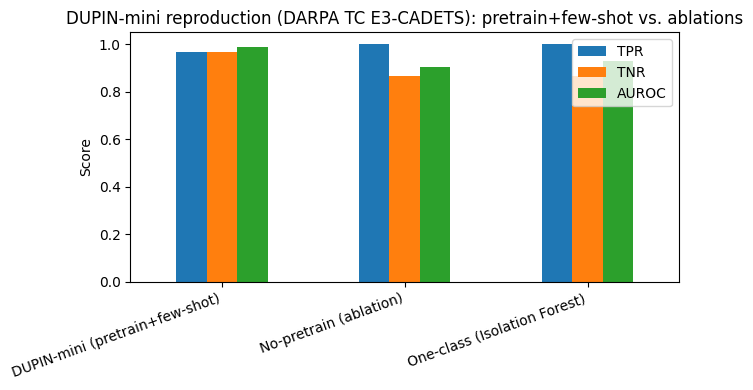

In [15]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(7, 4))
df[["TPR", "TNR", "AUROC"]].plot(kind="bar", ax=ax)
ax.set_ylim(0, 1.05)
ax.set_ylabel("Score")
ax.set_title("DUPIN-mini reproduction (DARPA TC E3-CADETS): pretrain+few-shot vs. ablations")
plt.xticks(rotation=20, ha="right")
plt.tight_layout()
plt.savefig("dupin_mini_comparison.png", dpi=150)
plt.show()

## 12. Notes for the write-up

Suggested points to discuss in your reproduction report:

1. **Setup honesty**: real DARPA TC E3-CADETS data (Backdoor Nginx attack,
   matching DUPIN's Attack ID 1), but via MAGIC's pre-processed pickles
   rather than raw CDM logs, with a 2-layer/32-dim GAT instead of the
   paper's 7-layer/128-dim, and node-level ego-subgraphs (via the paper's
   own Appendix E random-walk algorithm, gamma=40/delta=100) rather than the
   paper's full custom tokenizer (Section 3.1).
2. **Does the ordering hold?** Report whether
   `DUPIN-mini > No-pretrain > One-class` in AUROC, matching the paper's
   Table 3 (DUPIN beats MAGIC/AirTag) and Table 7 (pretrain beats
   no-pretrain) *directionally*.
3. **A labeling pitfall we hit and fixed**: an earlier version of this
   notebook chose known-malicious nodes as random-walk *starting points*
   for attack-labeled samples, which leaked the label into the input via
   the center node's own type and made all three approaches (including the
   label-blind one-class baseline) score a suspicious, uninformative 1.0
   AUROC. The current version samples starting nodes uniformly at random
   and labels the resulting subgraph only afterward, per DUPIN's own
   evaluation principle (Section 4, principle 2) against letting ground
   truth influence subgraph collection. This is worth describing in your
   report as a concrete illustration of the evaluation pitfall the paper
   warns about -- and of why it matters in practice, not just in theory.
4. **Ground truth provenance**: labels come from MAGIC's own node-level
   ground truth for E3-CADETS (their Appendix G methodology), not from
   DUPIN's own labeling -- worth stating explicitly, since DUPIN and MAGIC
   may not label identical entities even for the same campaign.
5. **Limitations vs. the real DUPIN**:
   - No custom path tokenizer (Section 3.1) -- node "names" here are just
     6 structural type classes, not semantic paths/process names like
     `vUgefal` or `nginx`.
   - Single test graph, single attack campaign -- no cross-dataset-source
     validation (Section 4 of the paper).
   - Subgraphs built via random-walk from a *single* center node per
     sample, rather than DUPIN's full coverage-guaranteeing iteration over
     every node in the graph.